# Homework 3
## Problem 1
(a) I expect "Peak Brightness Date/Time (UT)" to be numerical and discrete since it is inconvenient to have times between seconds or minutes. This should be an int. I expect "Latitude (deg.)", "Longitude (deg.)" to both be numerical and continuous since there is a continnuous measurement of geographic latitude and longitude, so it should bea float. Likewise, I expect "Altitude (km)", "Velocity Components (km/s)", "Total Radiated Energy (J)","Calculated Total Impact Energy (kt)" to be numerical and continuous float data types since they are all measurements and not in seperate categories.

In [13]:
# Examine data storage types of columns in fireball.csv
import pandas as pd
df = pd.read_csv('fireball.csv')
df.dtypes

Peak Brightness Date/Time (UT)             str
Latitude (deg.)                            str
Longitude (deg.)                           str
Altitude (km)                          float64
Velocity Components (km/s)                 str
Unnamed: 5                                 str
Unnamed: 6                                 str
Total Radiated Energy (J)              float64
Calculated Total Impact Energy (kt)    float64
dtype: object

My predictions were, for the most part, wrong. "Peak Brightness Date/Time (UT)", "Latitude (deg.)", and "Longitude (deg.)" were all strings. Also, there are two unnamed categories that I did not see (these are the respective v_y and v_z velocity components). I also predicted "Velocity Components (km/s)" wrong as I anticipated it being a float, but it is in string format. Additionally, "Latitude (deg.)" and "Longitude (deg.)" are both partly categorical as well, categorized into the degree and also N, E, S, or W.

(b)

In [14]:
# Convert data to suitable types

# Convert the date column to datetime
df['Peak Brightness Date/Time (UT)'] = pd.to_datetime(df['Peak Brightness Date/Time (UT)'], errors='coerce')

# Convert the latitude and longitude columns to numeric
lat = df["Latitude (deg.)"]
df["Latitude (deg.)"] = lat.str[:-1].astype(float) * lat.str[-1].map({"N": 1, "S": -1})

lon = df["Longitude (deg.)"]
df["Longitude (deg.)"] = lon.str[:-1].astype(float) * lon.str[-1].map({"E": 1, "W": -1})

# Convert the velocity columns to numeric using their actual names
df['Velocity Components (km/s)'] = pd.to_numeric(df['Velocity Components (km/s)'], errors='coerce')
df['Unnamed: 5'] = pd.to_numeric(df['Unnamed: 5'], errors='coerce')
df['Unnamed: 6'] = pd.to_numeric(df['Unnamed: 6'], errors='coerce')

# Rename the columns
df = df.rename(columns={
    "Peak Brightness Date/Time (UT)": "datetime",
	'Velocity Components (km/s)': 'vx',
	'Unnamed: 5': 'vy',
	'Unnamed: 6': 'vz',
    "Latitude (deg.)": "lat",
    "Longitude (deg.)": "lon",
    "Altitude (km)": "altitude",
    "Total Radiated Energy (J)": "rad_energy",
    "Calculated Total Impact Energy (kt)": "impact_energy"
})

df.to_csv('fireball_cleaned.csv', index=False)

(c)

Text(0, 0.5, 'Frequency of Fireball Events')

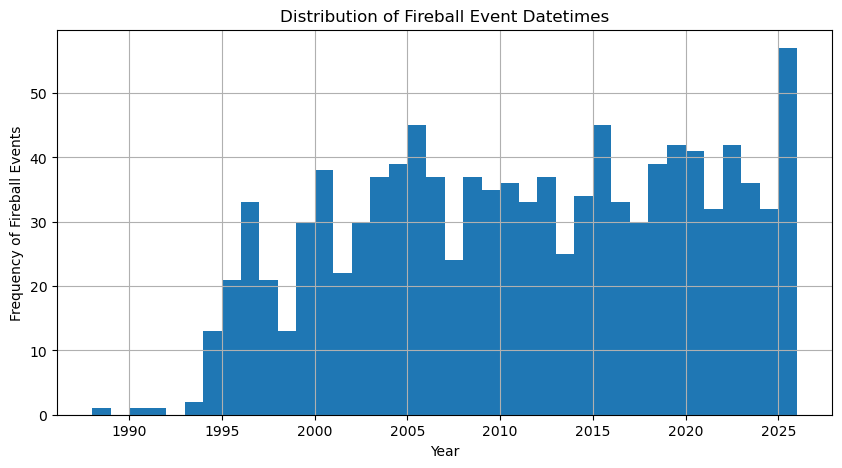

In [28]:
# Distribution of fireball events by year
plt = df['datetime'].dt.year.hist(bins=len(df['datetime'].dt.year.unique()), figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Datetimes')
plt.set_xlabel('Year')
plt.set_ylabel('Frequency of Fireball Events')

It seems that the database did not have much data before 2000. After 2000, there seems to be a steady frequency of around 30 fireball events per year, though there do seem to be dips every 5 years or so at 2001-2002, 2007-2008, and 2013-2014.

Text(0, 0.5, 'Frequency of Fireball Events')

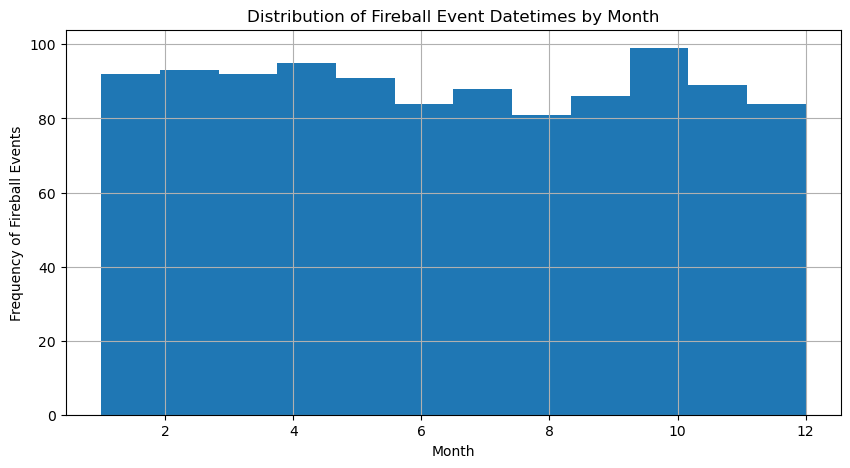

In [23]:
# Distribution of fireball events by month
plt = df['datetime'].dt.month.hist(bins=12, figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Datetimes by Month')
plt.set_xlabel('Month')
plt.set_ylabel('Frequency of Fireball Events')

The fireball events seem to be evenly distributed across the months, there there is a slight around late summer in August.

Text(0, 0.5, 'Frequency of Fireball Events')

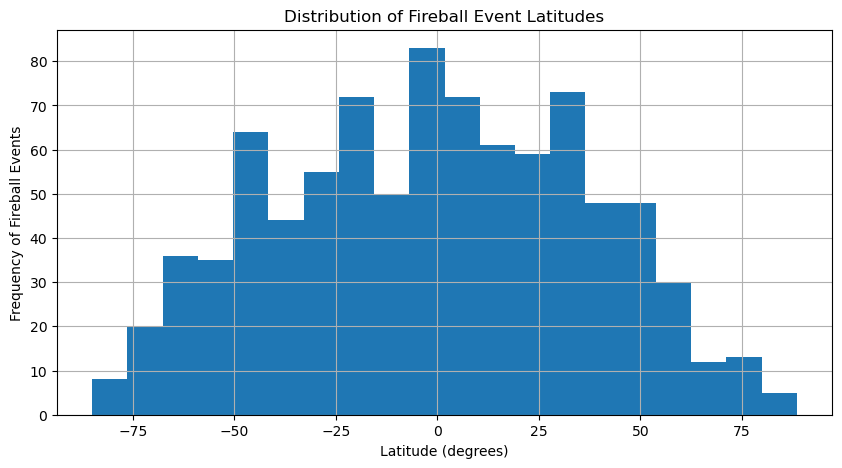

In [24]:
# Distribution of fireball events by latitude
plt = df['lat'].hist(bins=20, figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Latitudes')
plt.set_xlabel('Latitude (degrees)')
plt.set_ylabel('Frequency of Fireball Events')

There is a clear unimodal peak at a latitude of 0 degrees (the most impacts happen here). The further from 0 degrees we get, the less fireball events there are. This is a symmetrical distribution.

Text(0, 0.5, 'Frequency of Fireball Events')

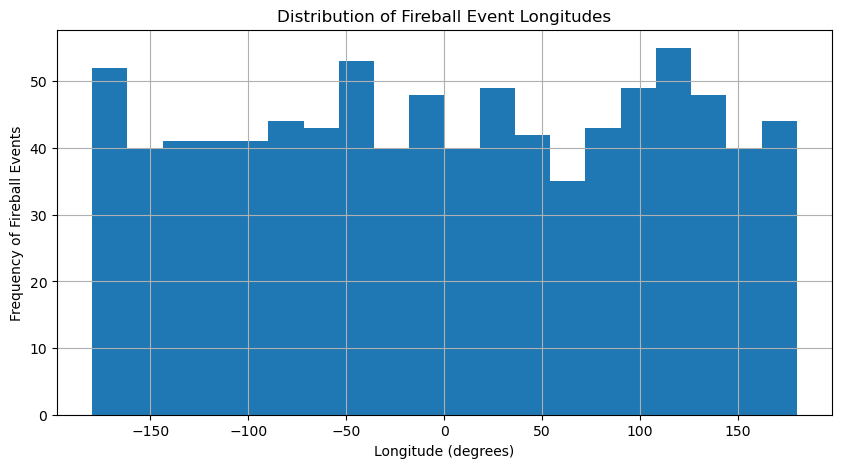

In [25]:
# Distribution of fireball events by longitude
plt = df['lon'].hist(bins=20, figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Longitudes')
plt.set_xlabel('Longitude (degrees)')
plt.set_ylabel('Frequency of Fireball Events')

The number of fireball events seems to be pretty uniformly destributed across longitude.

Text(0, 0.5, 'Frequency of Fireball Events')

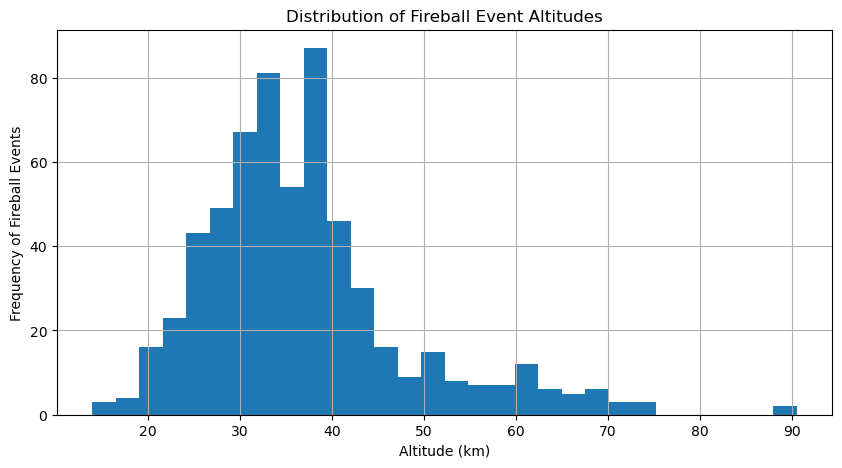

In [29]:
# Distribution of fireball events by altitude
plt = df['altitude'].hist(bins=30, figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Altitudes')
plt.set_xlabel('Altitude (km)')
plt.set_ylabel('Frequency of Fireball Events')

The distribution of fireball events by altitude seems to be right-skewed, withe a bimodal distribution (peaks around 30km and 40km). There is a gap around 80 km.

(d)

Outliers: Empty DataFrame
Columns: [datetime, lat, lon, altitude, vx, vy, vz, rad_energy, impact_energy]
Index: []


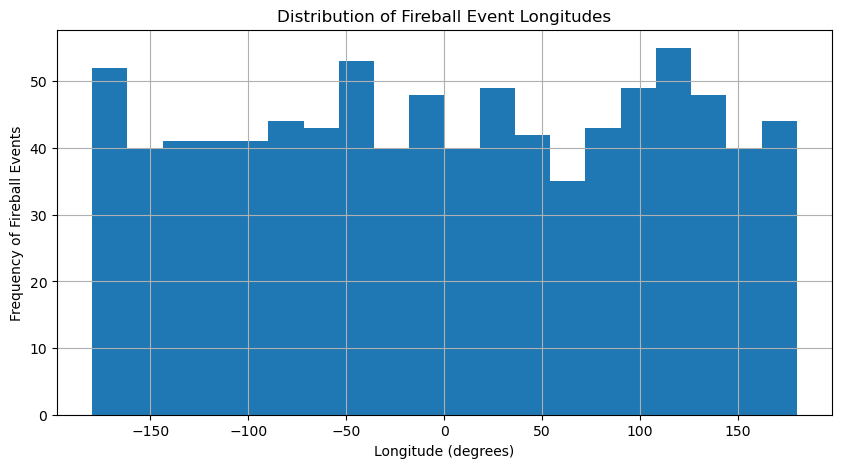

In [32]:
# Distribution of fireball events by longitude
plt = df['lon'].hist(bins=20, figsize=(10, 5))
plt.set_title('Distribution of Fireball Event Longitudes')
plt.set_xlabel('Longitude (degrees)')
plt.set_ylabel('Frequency of Fireball Events')

# Check for outliers in the longitude
df = pd.read_csv('fireball_cleaned.csv')
Q1 = df['lon'].quantile(0.25)
Q3 = df['lon'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Outliers: {df[(df['lon'] < lower_bound) | (df['lon'] > upper_bound)]}")

The longitude is centered, at 0 degrees with a pretty even spread. There seem to be no outliers based purely on the shape of the histogram shape, and using the 1.5*IQR rule, we see that there are no outliers in the longitude. This distribution is consistent with what expect. Moreover, since fireball events orbit the earth, I expect all longitudes (measured vertically) to be evenly covered. It makes sense that the histogram mirrors a uniform distribution.

(e) Make a Q-Q plot or an equivalent plot of the distribution of the latitudes of fireballs relative to
the theoretical distribution that fireballs occur at a density proportional to the cosine of latitude.

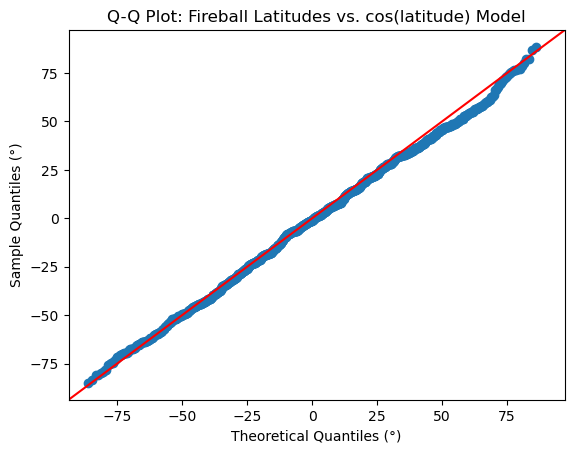

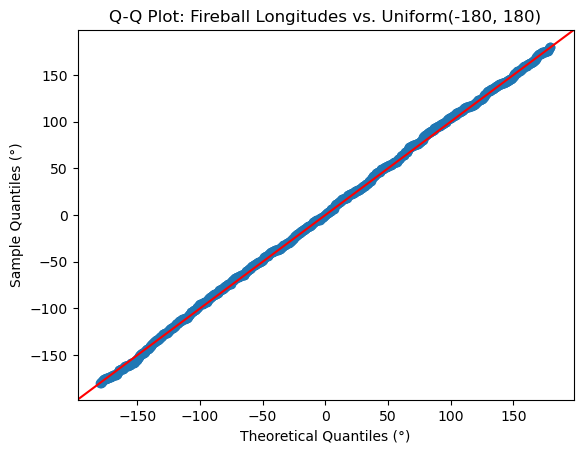

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot

# Signed coordinates: N and E positive, S and W negative
d = df.dropna(subset=['lat', 'lon'])
lat = d['lat']
lon = d['lon']

# Theoretical distribution: density proportional to cos(latitude), in degrees
class coslat_gen(stats.rv_continuous):
    def _pdf(self, x): return np.cos(np.radians(x)) * np.pi / 360
    def _cdf(self, x): return (1 + np.sin(np.radians(x))) / 2
    def _ppf(self, p): return np.degrees(np.arcsin(2 * p - 1))

coslat = coslat_gen(a=-90, b=90, name='coslat')

# Q-Q plot for latitude
qqplot(lat, dist=coslat, line='45')
plt.title('Q-Q Plot: Fireball Latitudes vs. cos(latitude) Model')
plt.xlabel('Theoretical Quantiles (°)')
plt.ylabel('Sample Quantiles (°)')
plt.show()

# Q-Q plot for longitude
qqplot(lon, dist=stats.uniform, loc=-180, scale=360, line='45')
plt.title('Q-Q Plot: Fireball Longitudes vs. Uniform(-180, 180)')
plt.xlabel('Theoretical Quantiles (°)')
plt.ylabel('Sample Quantiles (°)')
plt.show()

(f)

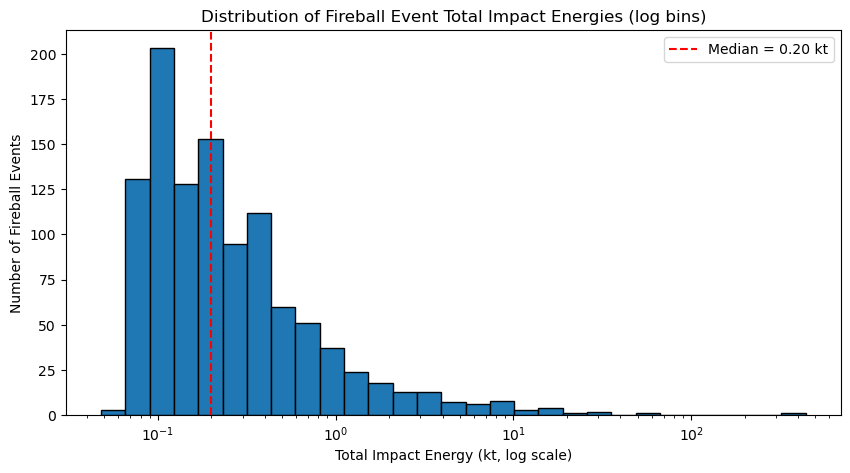

In [42]:
import numpy as np
import matplotlib.pyplot as plt

e = df['impact_energy'].dropna()
e = e[e > 0]  # log scale requires positive values

# 30 bins evenly spaced in log10(energy)
bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 30)

plt.figure(figsize=(10, 5))
plt.hist(e, bins=bins, edgecolor='black')
plt.xscale('log')
plt.axvline(e.median(), color='red', linestyle='--', label=f'Median = {e.median():.2f} kt')
plt.title('Distribution of Fireball Event Total Impact Energies (log bins)')
plt.xlabel('Total Impact Energy (kt, log scale)')
plt.ylabel('Number of Fireball Events')
plt.legend()
plt.show()

In [43]:
q1, med, q3 = e.quantile([0.25, 0.5, 0.75])
print(f"Median: {med:.3f} kt, Q1: {q1:.3f}, Q3: {q3:.3f}, IQR: {q3 - q1:.3f}")
print(f"Mean: {e.mean():.3f} kt (pulled up by the right tail)")

# Outliers using the 1.5*IQR rule on log10(energy)
le = np.log10(e)
lq1, lq3 = le.quantile([0.25, 0.75])
liqr = lq3 - lq1
outliers = e[(le < lq1 - 1.5 * liqr) | (le > lq3 + 1.5 * liqr)]
print(outliers.sort_values())

Median: 0.200 kt, Q1: 0.110, Q3: 0.410, IQR: 0.300
Mean: 1.124 kt (pulled up by the right tail)
910       3.1
784       3.2
857       3.3
59        3.4
627       3.5
467       3.5
574       3.8
103       3.8
157       3.8
793       3.9
399       3.9
279       4.3
819       4.6
543       4.9
1059      5.0
718       5.0
73        5.1
1073      5.2
263       6.0
112       6.5
487       6.9
162       7.0
108       7.1
935       7.3
446       7.6
325       7.9
865       8.8
864       8.8
895       9.0
559       9.7
965       9.8
481       9.8
202      12.0
382      13.0
783      13.0
691      14.0
579      14.0
1074     14.0
780      18.0
598      20.0
1069     30.0
605      33.0
284      49.0
485     441.0
Name: impact_energy, dtype: float64


The distribution of impact energies of the fireball events appears still right skewed, with a unimodal peak around 10^{-1}. It is centered at around a median of 0.200 kilotons, with a spread of 0.300 kilotons (the IQR). By the 1.5*IQR outlier rule, there are quite a few, with the event above 400 kilotons as the most obvious outlier. There are also several events with below 10 kt of energy.

(g)

Degrees plotted: 360
Mean events per degree: 2.466666666666667
Variance: 2.5711111111111107 (Poisson variance = mean)
Empty degrees: 27 expected: 30.6


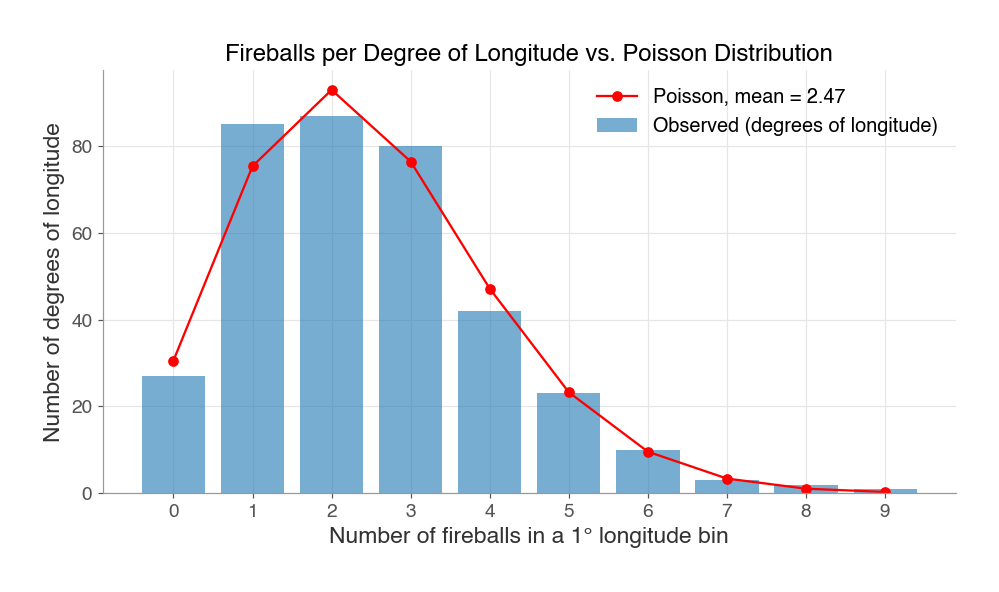

In [72]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

d = df.dropna(subset=['lon'])
lon = d['lon']

# Roundign
deg = np.floor(lon).astype(int)
deg[deg == 180] = -180

# Count fireballs
counts = np.bincount(deg + 180, minlength=360)   # length 360

# Histogram-of-the-histogram
k = np.arange(counts.max() + 1)
observed = np.bincount(counts, minlength=len(k))

mu = counts.mean()           # should be about 888/360 = 2.47
expected = 360 * stats.poisson.pmf(k, mu)

print("Degrees plotted:", observed.sum())   # should be 360
print("Mean events per degree:", mu)
print("Variance:", counts.var(), "(Poisson variance = mean)")
print("Empty degrees:", observed[0], "expected:", round(expected[0], 1))

plt.figure(figsize=(10, 5))
plt.bar(k, observed, width=0.8, alpha=0.6, label='Observed (degrees of longitude)')
plt.plot(k, expected, 'ro-', label=f'Poisson, mean = {mu:.2f}')
plt.xticks(k)
plt.xlabel('Number of fireballs in a 1° longitude bin')
plt.ylabel('Number of degrees of longitude')
plt.title('Fireballs per Degree of Longitude vs. Poisson Distribution')
plt.legend()
plt.show()

The poisson distribution seems to agree pretty well with the number of fireballs in each degree of longitude. There are slightly lower amount of number of degrees of longitude compared to the discrete poisson distribution's number of degrees of longitude for 0, 2, and 4 fireball events and a slightly higher amount of degrees of longitude compared to the amount of degrees of longitude which the poisson distribution predicts for and 3 fireball events in each 1 degree longitude bin. Otherwise, the poisson ditribution seems to match the observed events pretty well.

## Problem 2
### Visualization 1 & 2: Do more Heating Degree Days correlate to more snowfall on a year-to-year basis?
That is, do colder ("freezing") days mean it is more likely to see snow? Does it mean there is deeper snowfall measured?

Dropped seasons (incomplete data): [1997, 1998]
Number of seasons: 28


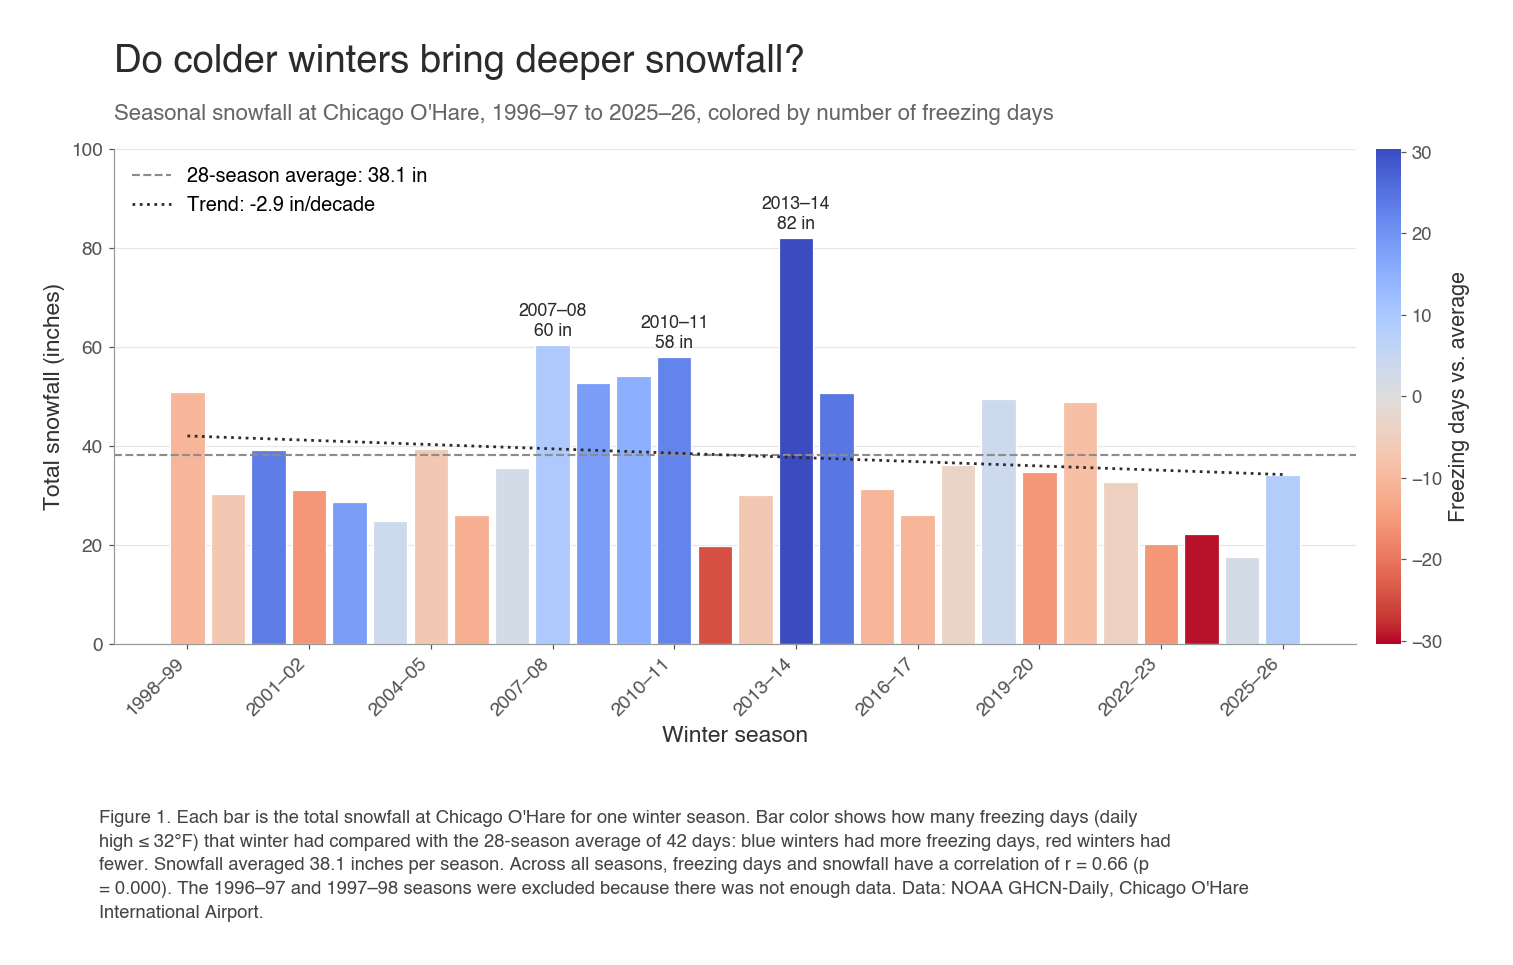

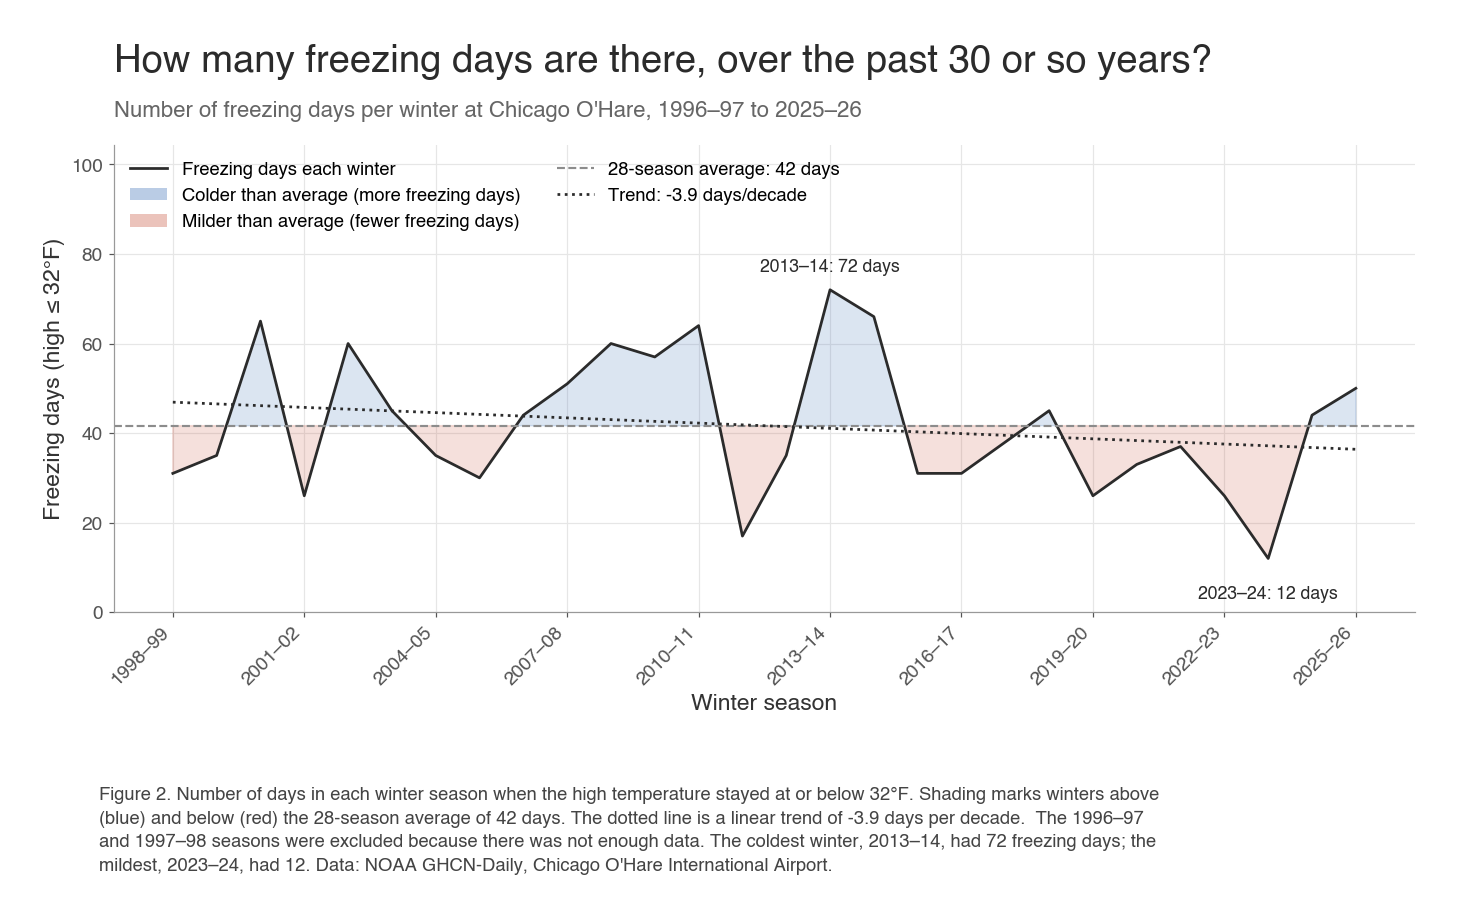

In [ ]:
# Visualization 1: Snowfall each winter over time, colored by freezing days
anom = seasons['FREEZE'] - mean_f
lim = np.abs(anom).max()
norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
cmap = plt.cm.coolwarm_r   # blue = more freezing days, red = fewer

fig, ax = plt.subplots(figsize=(13, 9))
fig.subplots_adjust(left=0.07, right=0.98, top=0.80, bottom=0.30)

ax.bar(seasons.index, seasons['SNOW'], color=cmap(norm(anom)),
       edgecolor='white', linewidth=0.8, width=0.85)
ax.axhline(mean_s, color=GRAY, linestyle='--', linewidth=1.4,
           label=f"{n}-season average: {mean_s:.1f} in")
ax.plot(seasons.index, snow_tr.intercept + snow_tr.slope * seasons.index,
        color=DARK, linestyle=':', linewidth=1.8,
        label=f"Trend: {snow_tr.slope*10:+.1f} in/decade")

ax.set_xticks(ticks)
ax.set_xticklabels([label(s) for s in ticks], rotation=45, ha='right')
ax.set_xlabel('Winter season')
ax.set_ylabel('Total snowfall (inches)')
plt.show()

# Visualization 2: Freezing days each winter over time
x, y = seasons.index.values, seasons['FREEZE'].values

fig, ax = plt.subplots(figsize=(13, 8.5))
fig.subplots_adjust(left=0.07, right=0.98, top=0.80, bottom=0.30)

# Shade above/below the average
ax.fill_between(x, y, mean_f, where=y >= mean_f, interpolate=True, color=BLUE, alpha=0.18)
ax.fill_between(x, y, mean_f, where=y < mean_f, interpolate=True, color=RED, alpha=0.18)
ax.plot(x, y, color=DARK, linewidth=1.8, zorder=2)

ax.axhline(mean_f, color=GRAY, linestyle='--', linewidth=1.4)
ax.plot(x, freeze_tr.intercept + freeze_tr.slope * x, color=DARK,
        linestyle=':', linewidth=1.8)

# Label the coldest and mildest winters
coldest, mildest = seasons['FREEZE'].idxmax(), seasons['FREEZE'].idxmin()
for s, offset in [(coldest, 12), (mildest, -26)]:
    ax.annotate(f"{label(s)}: {seasons.loc[s, 'FREEZE']} days",
                (s, seasons.loc[s, 'FREEZE']), xytext=(0, offset),
                textcoords='offset points', ha='center', fontsize=NOTE_SIZE, color=DARK)

ax.set_xticks(ticks)
ax.set_xticklabels([label(s) for s in ticks], rotation=45, ha='right')
ax.set_xlabel('Winter season')
ax.set_ylabel('Freezing days (high ≤ 32°F)')
ax.set_ylim(0, y.max() * 1.45)

### Visualization 3 (hourly): When does it snow? Snow by time of day

2020 downloaded
2021 downloaded
2022 downloaded
2023 downloaded
2024 downloaded
2025 downloaded


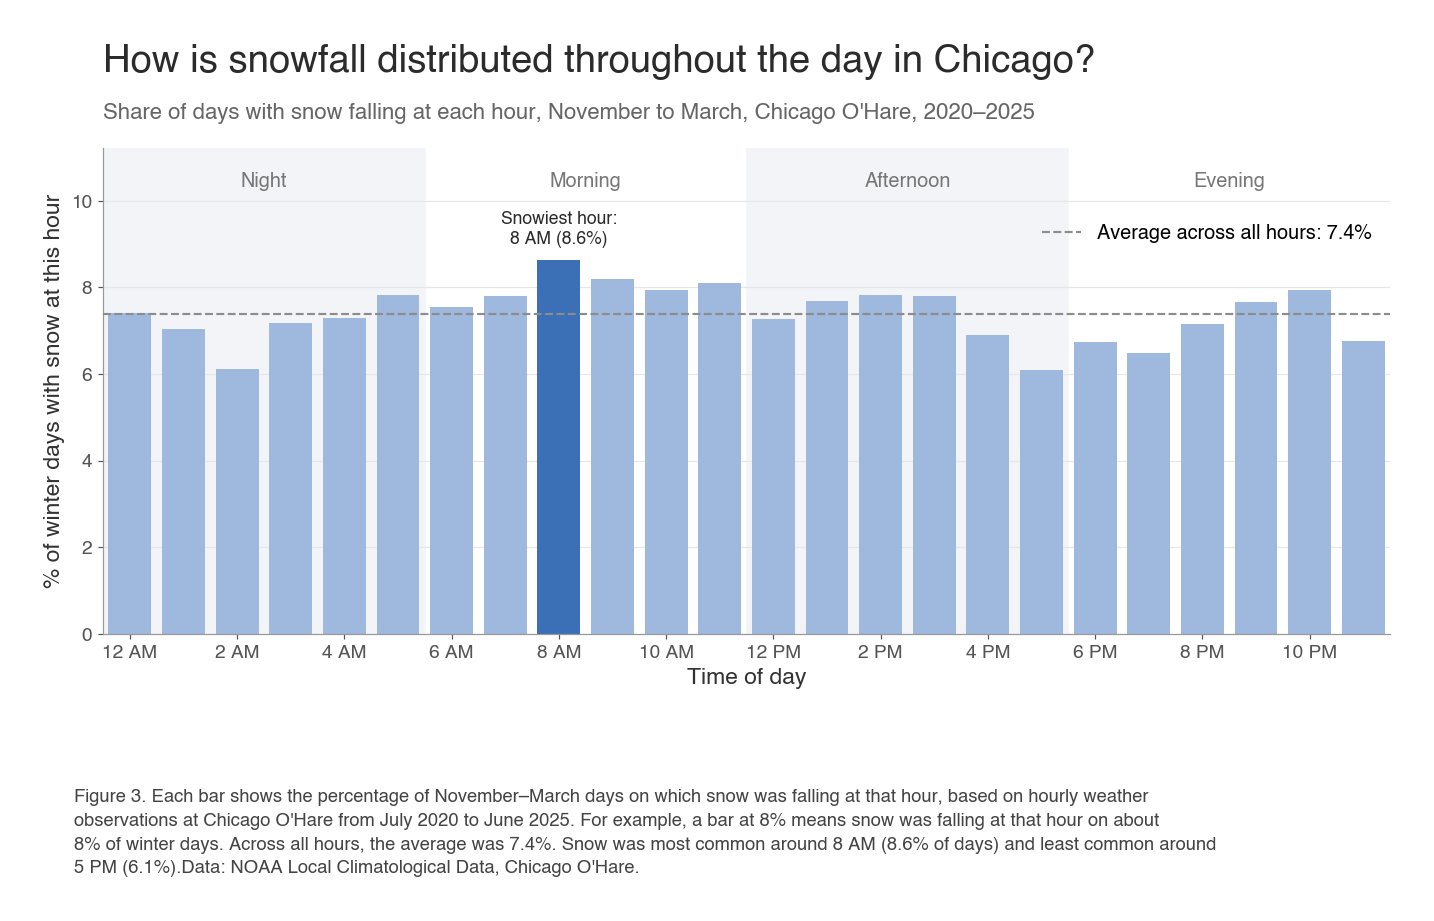

hour
0     7.4
1     7.0
2     6.1
3     7.2
4     7.3
5     7.8
6     7.5
7     7.8
8     8.6
9     8.2
10    7.9
11    8.1
12    7.3
13    7.7
14    7.8
15    7.8
16    6.9
17    6.1
18    6.7
19    6.5
20    7.2
21    7.7
22    7.9
23    6.8
Name: snowing, dtype: float64


In [ ]:
frames = []
for yr in range(2020, 2026):
    start = "2020-07-01" if yr == 2020 else f"{yr}-01-01"
    end   = "2025-06-30" if yr == 2025 else f"{yr}-12-31"
    url = ("https://www.ncei.noaa.gov/access/services/data/v1"
           "?dataset=local-climatological-data&stations=72530094846"
           f"&startDate={start}&endDate={end}&format=csv")
    frames.append(pd.read_csv(url, low_memory=False))
    print(yr, "downloaded")
raw = pd.concat(frames, ignore_index=True)

# Hour by hour reports
hr = raw[raw['REPORT_TYPE'].astype(str).str.strip() == 'FM-15'].copy()
hr['DATE'] = pd.to_datetime(hr['DATE'])
hr = hr[hr['DATE'].dt.month.isin([11, 12, 1, 2, 3])]
hr['hour'] = hr['DATE'].dt.hour
hr['snowing'] = hr['HourlyPresentWeatherType'].astype(str).str.contains(r'(?<!BL)SN', regex=True)

# % of hours with snow at each hour of the day
by_hour = hr.groupby('hour')['snowing'].mean() * 100
peak_h, low_h = by_hour.idxmax(), by_hour.idxmin()
hlabel = lambda h: f"{h % 12 or 12} {'AM' if h < 12 else 'PM'}"
fig, ax = plt.subplots(figsize=(13, 8.5))
fig.subplots_adjust(left=0.08, right=0.98, top=0.80, bottom=0.28)

# Background bands for parts of the day
bands = [(-0.5, 5.5, 'Night'), (5.5, 11.5, 'Morning'),
         (11.5, 17.5, 'Afternoon'), (17.5, 23.5, 'Evening')]
ymax = by_hour.max() * 1.3